In [794]:
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt

In [660]:
sns.set_style("darkgrid")

In [661]:
df = pd.read_csv("data/raw/2017_Yellow_Taxi_Trip_Data.csv")

| Field Name | Description | Values / Notes |
| :--- | :--- | :--- |
| **ID** | Trip identification number | |
| **VendorID** | A code indicating the TPEP provider that provided the record. | `1` = Creative Mobile Technologies, LLC<br>`2` = VeriFone Inc. |
| **tpep_pickup_datetime** | The date and time when the meter was engaged. | |
| **tpep_dropoff_datetime** | The date and time when the meter was disengaged. | |
| **Passenger_count** | The number of passengers in the vehicle. | Driver-entered value. |
| **Trip_distance** | The elapsed trip distance in miles reported by the taximeter. | |
| **PULocationID** | TLC Taxi Zone in which the taximeter was engaged. | |
| **DOLocationID** | TLC Taxi Zone in which the taximeter was disengaged. | |
| **RateCodeID** | The final rate code in effect at the end of the trip. | `1` = Standard rate<br>`2` = JFK<br>`3` = Newark<br>`4` = Nassau or Westchester<br>`5` = Negotiated fare<br>`6` = Group ride |
| **Store_and_fwd_flag** | Indicates whether the trip record was held in vehicle memory before being sent to the vendor ("store and forward") due to a lack of server connection. | `Y` = Store and forward trip<br>`N` = Not a store and forward trip |
| **Payment_type** | A numeric code signifying how the passenger paid for the trip. | `1` = Credit card<br>`2` = Cash<br>`3` = No charge<br>`4` = Dispute<br>`5` = Unknown<br>`6` = Voided trip |
| **Fare_amount** | The time-and-distance fare calculated by the meter. | |
| **Extra** | Miscellaneous extras and surcharges. | Currently includes the $0.50 and $1 rush hour and overnight charges. |
| **MTA_tax** | MTA tax automatically triggered based on the metered rate in use. | $0.50 |
| **Improvement_surcharge** | Improvement surcharge assessed trips at the flag drop. | $0.30 (began in 2015) |
| **Tip_amount** | Tip amount. | Automatically populated for credit card tips. Cash tips are not included. |
| **Tolls_amount** | Total amount of all tolls paid in trip. | |
| **Total_amount** | The total amount charged to passengers. | Does not include cash tips. |

In [662]:
df.shape

(22699, 18)

In [663]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             22699 non-null  int64  
 1   VendorID               22699 non-null  int64  
 2   tpep_pickup_datetime   22699 non-null  object 
 3   tpep_dropoff_datetime  22699 non-null  object 
 4   passenger_count        22699 non-null  int64  
 5   trip_distance          22699 non-null  float64
 6   RatecodeID             22699 non-null  int64  
 7   store_and_fwd_flag     22699 non-null  object 
 8   PULocationID           22699 non-null  int64  
 9   DOLocationID           22699 non-null  int64  
 10  payment_type           22699 non-null  int64  
 11  fare_amount            22699 non-null  float64
 12  extra                  22699 non-null  float64
 13  mta_tax                22699 non-null  float64
 14  tip_amount             22699 non-null  float64
 15  to

In [664]:
df.describe()

,Unnamed: 0,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
count,2.269900e+04,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000
mean,5.675849e+07,1.556236,1.642319,2.913313,1.043394,162.412353,161.527997,1.336887,13.026629,0.333275,0.497445,1.835781,0.312542,0.299551,16.310502
std,3.274493e+07,0.496838,1.285231,3.653171,0.708391,66.633373,70.139691,0.496211,13.243791,0.463097,0.039465,2.800626,1.399212,0.015673,16.097295
min,1.212700e+04,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,-120.000000,-1.000000,-0.500000,0.000000,0.000000,-0.300000,-120.300000
25%,2.852056e+07,1.000000,1.000000,0.990000,1.000000,114.000000,112.000000,1.000000,6.500000,0.000000,0.500000,0.000000,0.000000,0.300000,8.750000
50%,5.673150e+07,2.000000,1.000000,1.610000,1.000000,162.000000,162.000000,1.000000,9.500000,0.000000,0.500000,1.350000,0.000000,0.300000,11.800000
75%,8.537452e+07,2.000000,2.000000,3.060000,1.000000,233.000000,233.000000,2.000000,14.500000,0.500000,0.500000,2.450000,0.000000,0.300000,17.800000
max,1.134863e+08,2.000000,6.000000,33.960000,99.000000,265.000000,265.000000,4.000000,999.990000,4.500000,0.500000,200.000000,19.100000,0.300000,1200.290000


## Data Cleaning

In [665]:
df.duplicated().sum()

np.int64(0)

In [666]:
useless_features = [
    "Unnamed: 0",
    "PULocationID",
    "DOLocationID",
]  # Useless features identified initially

In [667]:
df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"])
df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"])

In [668]:
df[df.tpep_pickup_datetime >= df.tpep_dropoff_datetime].shape[0]

27

27 Data points have pickup time later than or the same as drop time which is impossible

In [669]:
df[df.total_amount < 0].shape[0]

14

14 Data points where total_amount is negative

In [670]:
df[df.passenger_count < 1].shape[0]

33

33 Data points where number of passengers are 0

In [671]:
df[df.trip_distance < 0.1].shape[0]

187

187 data points where trip distances are too short, (<0.1 miles) and zero in cases

In [672]:
df["sum_amount"] = round(
    df.fare_amount
    + df.extra
    + df.mta_tax
    + df.tip_amount
    + df.tolls_amount
    + df.improvement_surcharge,
    2,
)

df["total_minus_sum"] = df.total_amount - df.sum_amount

In [673]:
df[df.sum_amount != df.total_amount].shape[0]

43

43 People paid more than their sum amount, either 1.95 more or 4.95 more suggesting there's a hidden additional cost being totaled in the the total_amount that is not featured in the data.

In [674]:
df[df.RatecodeID == 99]

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,sum_amount,total_minus_sum
12501,31724098,1,2017-04-18 17:47:58,2017-04-18 17:47:58,0,0.0,99,N,264,264,1,77.2,0.0,0.5,0.0,0.0,0.3,78.0,78.0,0.0


Ratecode 99, where only 4 are possible

In [675]:
anomalous_mask = (
    (df.tpep_pickup_datetime >= df.tpep_dropoff_datetime)
    | (df.total_amount < 0)
    | (df.passenger_count < 1)
    | (df.trip_distance < 0.1)
    | (df.sum_amount != df.total_amount)
    | (df.RatecodeID == 99)
)

In [676]:
df = df[~anomalous_mask]

In [677]:
df.shape

(22426, 20)

### Payment type

| Field Name | Description | Values / Notes |
| :--- | :--- | :--- |
| **Payment_type** | A numeric code signifying how the passenger paid for the trip. | `1` = Credit card<br>`2` = Cash<br>`3` = No charge<br>`4` = Dispute  |

In [678]:
df.payment_type.value_counts()

payment_type
1    15127
2     7169
3       93
4       37
Name: count, dtype: int64

In [679]:
df.payment_type.value_counts(normalize=True)

payment_type
1    0.674530
2    0.319674
3    0.004147
4    0.001650
Name: proportion, dtype: float64

67.2% payments are made through credit card

32.0% payments by cash

In [680]:
df.groupby("payment_type")["passenger_count"].agg(["mean", "median"])

,mean,median
payment_type,,
1,1.624579,1.0
2,1.696192,1.0
3,1.322581,1.0
4,1.189189,1.0


In [681]:
payment_data = df.groupby("payment_type")["total_amount"].agg(
    ["mean", "median", "min", "max"]
)
payment_data.index = ["credit", "cash", "no_chrg", "dispute"]
payment_data

,mean,median,min,max
credit,17.528835,12.95,3.8,1200.29
cash,13.525036,9.80,0.0,157.06
no_chrg,15.714301,10.80,0.3,78.30
dispute,17.404324,11.30,3.8,64.32


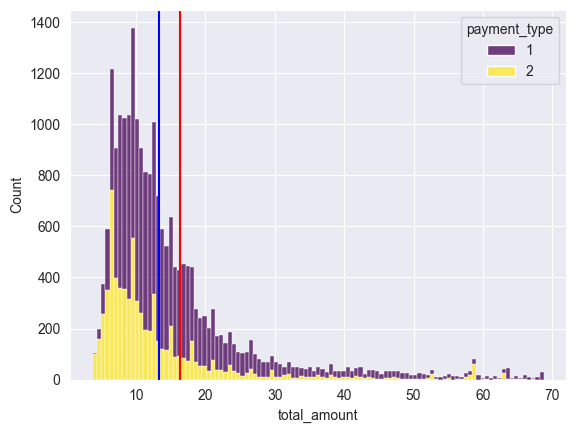

In [682]:
credit_data = (
    df[(df["payment_type"] == 1) | (df["payment_type"] == 2)][
        ["total_amount", "payment_type"]
    ]
    .sort_values("total_amount")
    .iloc[20:22000, :]
)

sns.histplot(
    data=credit_data,
    x="total_amount",
    hue="payment_type",
    multiple="stack",
    palette="viridis",
)
plt.axvline(
    credit_data[credit_data["payment_type"] == 1]["total_amount"].mean(),
    color="r",
)
plt.axvline(
    credit_data[credit_data["payment_type"] == 2]["total_amount"].mean(),
    color="b",
)
plt.show()

In [683]:
grp_A = df[df["payment_type"] == 1]["total_amount"]
grp_B = df[df["payment_type"] == 2]["total_amount"]

t_stat, p_value = stats.ttest_ind(grp_A, grp_B)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

T-statistic: 18.0925
P-value: 0.0000


difference between total_amount means of payment_type group a (credit card) and group b (cash) are *statistically significant* (p << 0.05)

### VendorID

In [684]:
df["VendorID"].value_counts()

VendorID
2    12469
1     9957
Name: count, dtype: int64

In [685]:
df.groupby("VendorID")["passenger_count"].agg(["mean", "median"])

,mean,median
VendorID,,
1,1.263131,1.0
2,1.950838,1.0


In [686]:
df.groupby("VendorID")["total_amount"].agg(["mean", "median"])

,mean,median
VendorID,,
1,16.289682,11.8
2,16.202477,11.8


In [687]:
grp_A = df[df["VendorID"] == 1]["total_amount"]
grp_B = df[df["VendorID"] == 2]["total_amount"]

t_stat, p_value = stats.ttest_ind(grp_A, grp_A)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

T-statistic: 0.0000
P-value: 1.0000


difference between total_amount means of vendorID group 1 and group 2 are *NOT* statistically significant (p > 0.05)

In [688]:
useless_features.append("VendorID")

---

### RateCodeID

| **RateCodeID** | The final rate code in effect at the end of the trip. 

`1` = Standard rate<br>`2` = JFK<br>`3` = Newark<br>`4` = Nassau or Westchester|<br>`5` = Negotiated fare

Ratecode (or Rate Code) is a specific identifier or setting used by a taximeter to determine how a fare is calculated. It dictates the base rate, per-mile/kilometer charges, time-waiting fees, and any flat-rate rules that apply to your trip.Ratecodes are designed to automatically adjust the taximeter based on factors like the destination, time of day, or special travel zones.Why Ratecodes MatterCalculating Cost: Depending on where you go, standard time-and-distance rates might not apply. A ratecode tells the meter exactly what formula to use.Standardization: It ensures drivers and passengers remain on the same page by utilizing officially regulated, municipality-approved tariffs.

In [689]:
df["RatecodeID"].value_counts().sort_index()

RatecodeID
1    21857
2      491
3       36
4        8
5       34
Name: count, dtype: int64

In [690]:
df.groupby("RatecodeID")["passenger_count"].agg(["mean", "median"])

,mean,median
RatecodeID,,
1,1.643272,1.0
2,1.716904,1.0
3,1.916667,1.0
4,1.250000,1.0
5,1.852941,2.0


In [691]:
dg = df.groupby("RatecodeID")["total_amount"].agg(["mean", "median"])
dg

,mean,median
RatecodeID,,
1,14.827446,11.760
2,65.581711,66.000
3,88.404167,94.080
4,81.383750,84.735
5,120.803529,86.800


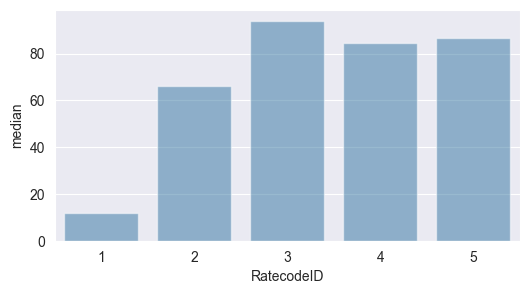

In [692]:
plt.figure(figsize=(6, 3))
# sns.barplot(data=dg[:5], x="RatecodeID", y="mean", alpha=0.5)
sns.barplot(data=dg[:5], x="RatecodeID", y="median", alpha=0.5);


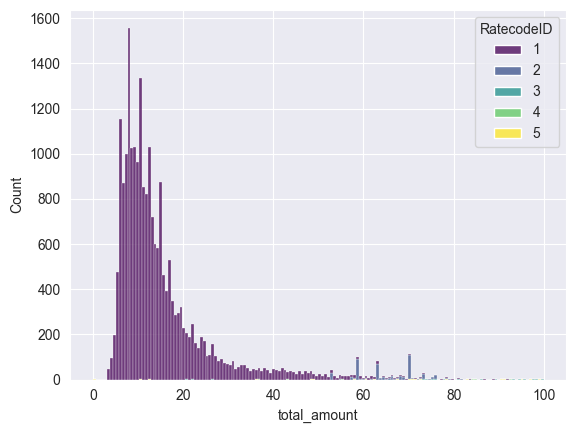

In [693]:
sns.histplot(
    data=df[df.total_amount.between(0, 100)],
    x="total_amount",
    hue="RatecodeID",
    palette="viridis",
    multiple="stack",
);

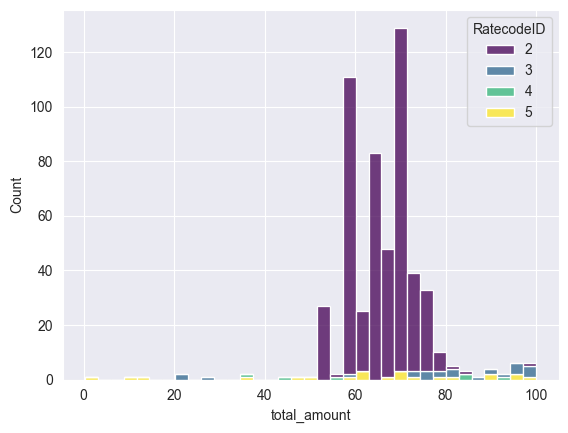

In [694]:
sns.histplot(
    data=df[(df.total_amount.between(0, 100)) & (df.RatecodeID > 1)],
    x="total_amount",
    hue="RatecodeID",
    palette="viridis",
    multiple="stack",
);

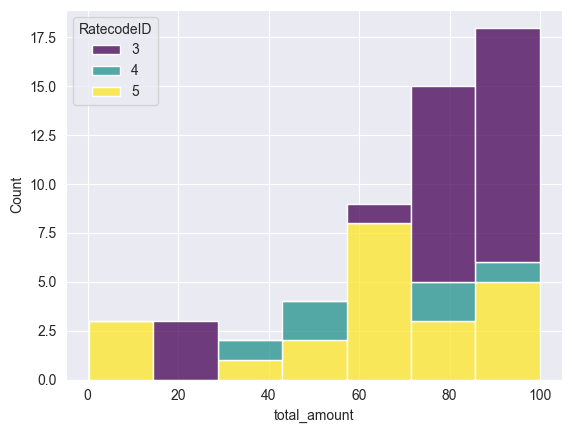

In [695]:
sns.histplot(
    data=df[(df.total_amount.between(0, 100)) & (df.RatecodeID > 2)],
    x="total_amount",
    hue="RatecodeID",
    palette="viridis",
    multiple="stack",
);

Clear distinction between ratecodeids, different ids affect prices

### store_and_fwd_flag

In [696]:
df["store_and_fwd_flag"].value_counts()

store_and_fwd_flag
N    22328
Y       98
Name: count, dtype: int64

In [697]:
df.groupby("store_and_fwd_flag")["passenger_count"].agg(["mean", "median"])

,mean,median
store_and_fwd_flag,,
N,1.647304,1.0
Y,1.234694,1.0


In [698]:
df.groupby("store_and_fwd_flag")["total_amount"].agg(["mean", "median"])

,mean,median
store_and_fwd_flag,,
N,16.231718,11.800
Y,18.400408,13.815


In [699]:
grp_a = df[df["store_and_fwd_flag"] == "N"]["total_amount"]
grp_b = df[df["store_and_fwd_flag"] == "Y"]["total_amount"]
t_stat, p_value = stats.ttest_ind(grp_a, grp_b)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

T-statistic: -1.3780
P-value: 0.1682


difference between total_amount means of store_and_fwd_flag group Y and group N are *NOT* statistically significant (p > 0.05)

In [700]:
useless_features.append("store_and_fwd_flag")

---

### Passenger ID

In [701]:
df["passenger_count"].value_counts()

passenger_count
1    15942
2     3267
5     1135
3      947
6      685
4      450
Name: count, dtype: int64

In [702]:
df.groupby("passenger_count")["total_amount"].agg(["median", "mean"])

,median,mean
passenger_count,,
1,11.80,16.035647
2,12.30,17.144824
3,12.36,16.589736
4,11.76,16.492222
5,11.80,16.180335
6,11.76,16.169299


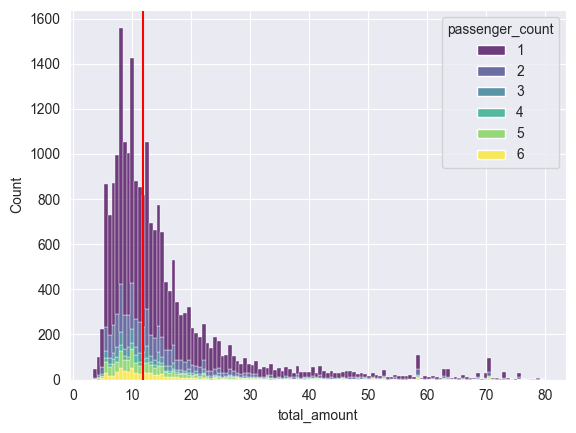

In [703]:
sns.histplot(
    data=df[(df["total_amount"].between(1, 80)) & (df["passenger_count"] > 0)],
    x="total_amount",
    hue="passenger_count",
    palette="viridis",
    multiple="stack",
)
plt.axvline(df.total_amount.median(), color="red");


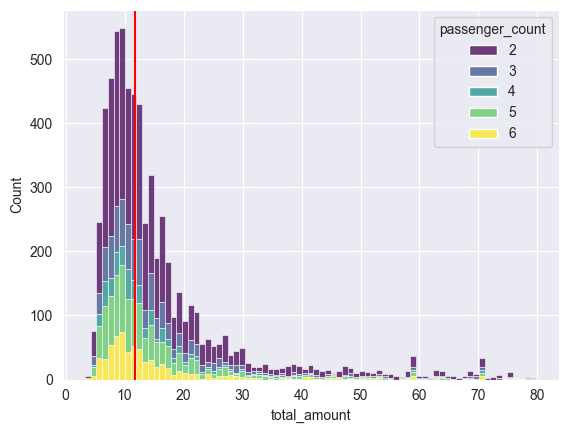

In [704]:
sns.histplot(
    data=df[(df["total_amount"].between(1, 80)) & (df["passenger_count"] > 1)],
    x="total_amount",
    hue="passenger_count",
    palette="viridis",
    multiple="stack",
)
plt.axvline(df.total_amount.median(), color="red");

passenger count doesnt have any effect on total_amount

In [705]:
useless_features.append("passenger_count")

---

# Numeric features

### Extra

In [706]:
df.extra.describe()

count    22426.000000
mean         0.334366
std          0.462146
min          0.000000
25%          0.000000
50%          0.000000
75%          0.500000
max          4.500000
Name: extra, dtype: float64

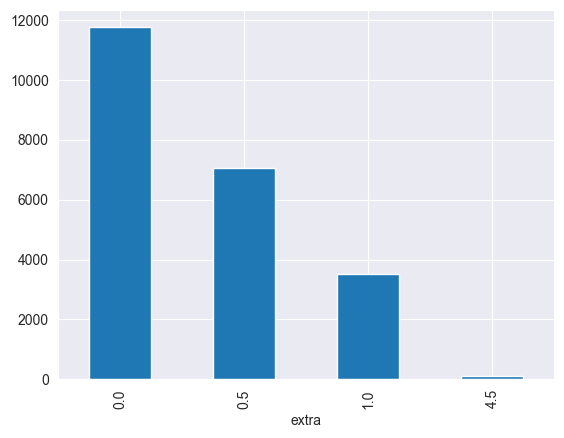

In [707]:
df.extra.value_counts().plot(kind="bar");

### mta_tax

In [708]:
df.mta_tax.describe()

count    22426.000000
mean         0.498595
std          0.026464
min          0.000000
25%          0.500000
50%          0.500000
75%          0.500000
max          0.500000
Name: mta_tax, dtype: float64

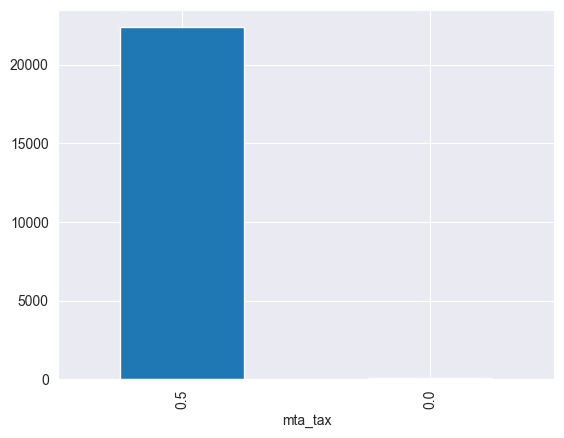

In [709]:
df.mta_tax.value_counts().plot(kind="bar");

### tip_amount

In [710]:
df.tip_amount.describe()

count    22426.000000
mean         1.829408
std          2.763930
min          0.000000
25%          0.000000
50%          1.360000
75%          2.450000
max        200.000000
Name: tip_amount, dtype: float64

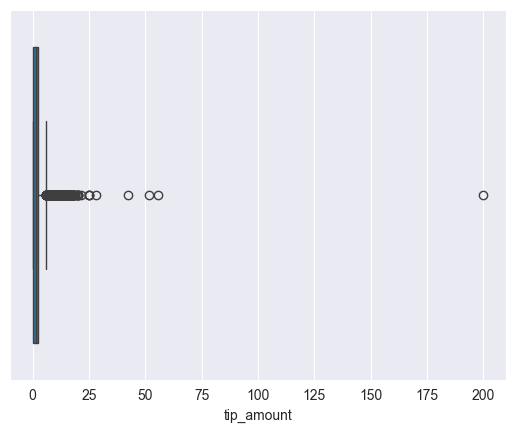

In [711]:
sns.boxplot(data=df, x="tip_amount");

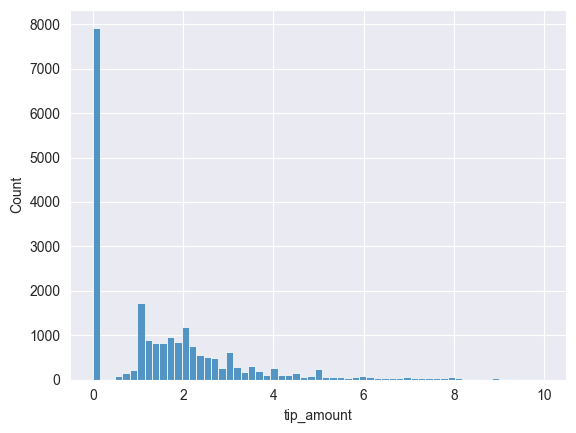

In [712]:
sns.histplot(data=df[df.tip_amount < 10], x="tip_amount");

Most people dont tip

### tolls_amount

In [713]:
df.tolls_amount.describe()

count    22426.000000
mean         0.309312
std          1.387061
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         19.100000
Name: tolls_amount, dtype: float64

In [714]:
df[df.tolls_amount > 0].sort_values("tolls_amount", ascending=False)[
    [
        "PULocationID",
        "DOLocationID",
        "tolls_amount",
    ]
].iloc[:15]

,PULocationID,DOLocationID,tolls_amount
5271,164,1,19.10
16705,161,1,18.28
4885,246,1,18.26
18888,230,1,18.00
11560,164,1,17.50
7627,48,118,17.28
17959,107,23,16.62
316,170,1,16.50
17046,230,1,16.50
6064,138,1,16.26


In [715]:
df.groupby("DOLocationID")["tolls_amount"].median().sort_values(ascending=False)[:10]

DOLocationID
23     14.07
1      12.75
118     8.64
16      5.76
135     5.76
51      5.76
182     5.76
138     5.76
194     5.76
132     5.54
Name: tolls_amount, dtype: float64

In [716]:
df.groupby("PULocationID")["tolls_amount"].median().sort_values(ascending=False)[:10]


PULocationID
10     5.76
216    5.76
258    5.76
138    5.76
93     5.54
28     2.88
228    2.88
130    2.88
17     0.00
24     0.00
Name: tolls_amount, dtype: float64

Drop OFF location ID 1 amd 23 have high tolls

### improvement_surcharge

In [717]:
df.improvement_surcharge.describe()

count    22426.000000
mean         0.299987
std          0.002003
min          0.000000
25%          0.300000
50%          0.300000
75%          0.300000
max          0.300000
Name: improvement_surcharge, dtype: float64

In [718]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 22426 entries, 0 to 22698
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Unnamed: 0             22426 non-null  int64         
 1   VendorID               22426 non-null  int64         
 2   tpep_pickup_datetime   22426 non-null  datetime64[ns]
 3   tpep_dropoff_datetime  22426 non-null  datetime64[ns]
 4   passenger_count        22426 non-null  int64         
 5   trip_distance          22426 non-null  float64       
 6   RatecodeID             22426 non-null  int64         
 7   store_and_fwd_flag     22426 non-null  object        
 8   PULocationID           22426 non-null  int64         
 9   DOLocationID           22426 non-null  int64         
 10  payment_type           22426 non-null  int64         
 11  fare_amount            22426 non-null  float64       
 12  extra                  22426 non-null  float64       
 13  mta_ta

In [719]:
useless_features.extend(
    [
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "improvement_surcharge",
        "total_amount",
        "sum_amount",
        "total_minus_sum",
        "payment_type",
    ]
)

In [720]:
useless_features

['Unnamed: 0',
 'PULocationID',
 'DOLocationID',
 'VendorID',
 'store_and_fwd_flag',
 'passenger_count',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'sum_amount',
 'total_minus_sum',
 'payment_type']

In [721]:
df.groupby("PULocationID")["fare_amount"].agg(["mean", "median"]).sort_values(
    by="median", ascending=False
)[:15]

,mean,median
PULocationID,,
1,152.000000,152.00
70,56.890000,75.00
93,45.142857,52.00
10,52.000000,52.00
258,52.000000,52.00
132,46.111868,52.00
216,52.000000,52.00
35,39.000000,39.00
130,35.250000,35.25


In [722]:
df.groupby("DOLocationID")["fare_amount"].agg(["mean", "median"]).sort_values(
    by="median", ascending=False
)[:15]

,mean,median
DOLocationID,,
219,71.500000,71.50
1,73.828125,69.50
23,64.750000,64.75
29,59.000000,59.00
18,58.000000,58.00
86,46.166667,57.00
265,59.872075,55.50
210,55.000000,55.00
132,50.066146,52.00


In [723]:
df[["PULocationID", "DOLocationID", "fare_amount", "trip_distance"]].sort_values(
    by="trip_distance", ascending=False
)[:15]

,PULocationID,DOLocationID,fare_amount,trip_distance
9280,132,265,150.00,33.96
13861,229,265,200.01,33.92
6064,138,1,107.00,32.72
10291,138,265,131.00,31.95
29,132,23,80.00,30.83
18130,132,220,90.50,30.50
5792,132,158,52.00,30.33
15350,13,132,52.00,28.23
10302,90,132,52.00,28.20
2592,261,132,52.00,27.97


Pickup and Drop locations could be a predictor but idk how to use them just yet, for now I will drop them

---

# Dropping useless features

In [724]:
df = df.drop(useless_features, axis=1)

continuing our analysis of other features

## Fare amount

In [725]:
df.fare_amount.describe()

count    22426.000000
mean        12.969527
std         12.660334
min          0.000000
25%          6.500000
50%          9.500000
75%         14.500000
max        999.990000
Name: fare_amount, dtype: float64

fare_amount 999 obvious outlier

In [726]:
df[df["fare_amount"] < 1]

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,RatecodeID,fare_amount
4061,2017-08-12 20:49:29,2017-08-12 21:18:50,4.50,5,0.01
4402,2017-12-20 16:06:53,2017-12-20 16:47:50,7.06,1,0.00
19067,2017-07-10 14:40:09,2017-07-10 14:40:59,0.10,5,0.00
21842,2017-04-18 16:55:29,2017-04-18 18:29:44,20.40,5,0.00


In [727]:
q1, q3 = 6.5, 14.5

iqr = q3 - q1

upper_limit = q3 + iqr * 1.5

fare_upper_limit = df["fare_amount"].quantile(0.99) + iqr

In [728]:
fare_upper_limit

np.float64(60.0)

In [729]:
df[df["fare_amount"] > fare_upper_limit].shape[0]

80

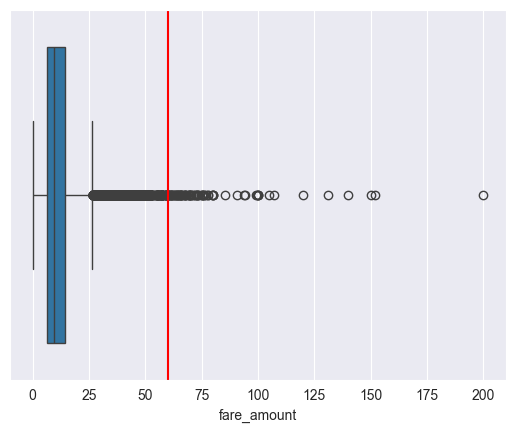

In [730]:
sns.boxplot(data=df[df.fare_amount < 999], x="fare_amount")
plt.axvline(fare_upper_limit, color="r");

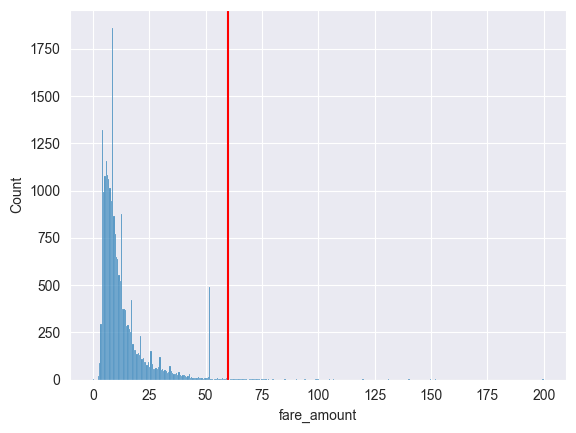

In [731]:
sns.histplot(data=df[df.fare_amount < 999], x="fare_amount")
plt.axvline(fare_upper_limit, color="r");

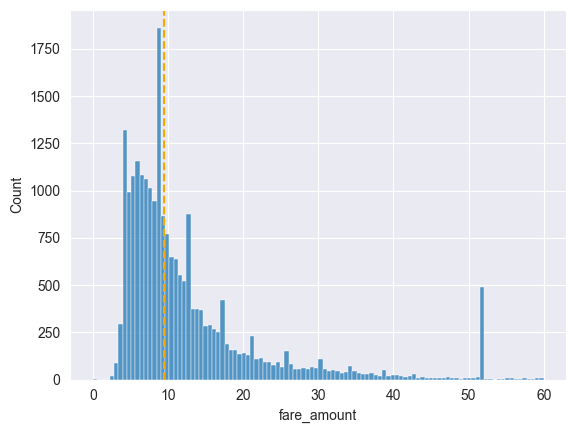

In [732]:
sns.histplot(data=df[df.fare_amount.between(0, fare_upper_limit)], x="fare_amount")
plt.axvline(df.fare_amount.median(), color="orange", linestyle="dashed");

In [733]:
df.fare_amount.value_counts().sort_index().iloc[100:106]

fare_amount
51.0      7
51.5      6
52.0    492
52.5      4
53.0      4
54.0      2
Name: count, dtype: int64

So there's a clear spike at fare = 52 for some reason

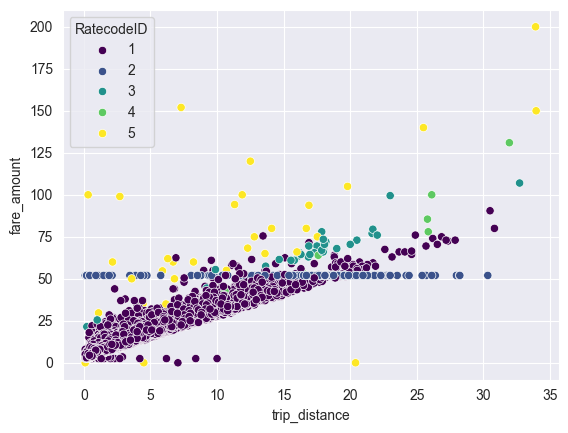

In [734]:
sns.scatterplot(
    data=df[df.fare_amount < 999],
    x="trip_distance",
    y="fare_amount",
    hue="RatecodeID",
    palette="viridis",
);

Most Outliers come from ratecode 5 (negotiated fares)

In [735]:
df.RatecodeID.value_counts()

RatecodeID
1    21857
2      491
3       36
5       34
4        8
Name: count, dtype: int64

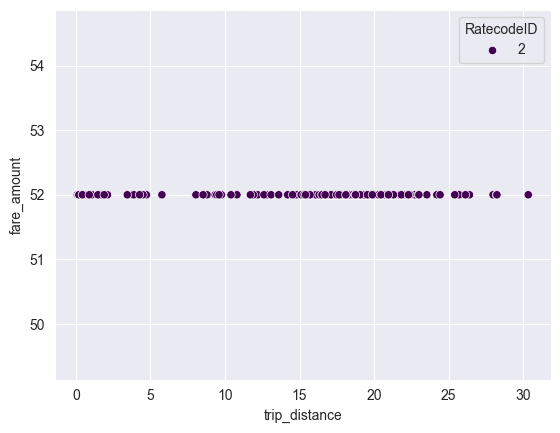

In [736]:
sns.scatterplot(
    data=df[df.RatecodeID == 2],
    x="trip_distance",
    hue="RatecodeID",
    y="fare_amount",
    palette="viridis",
);

Very Clearly when your Ratecode ID is 2 (JFK) you only pay 52, no matter the distance


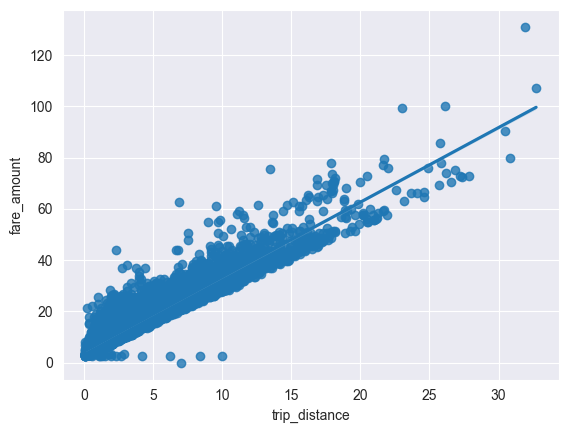

In [737]:
# removing ratecode 2 and 5 from data to see if they remove all outliers

sns.regplot(
    data=df[(df.RatecodeID != 5) & (df.RatecodeID != 2)],
    x="trip_distance",
    y="fare_amount",
    # hue="RatecodeID",
    # palette="viridis",
);

### Trip Distance (in miles)

In [738]:
df["trip_distance"].describe()

count    22426.000000
mean         2.935161
std          3.656338
min          0.100000
25%          1.000000
50%          1.630000
75%          3.090000
max         33.960000
Name: trip_distance, dtype: float64

In [739]:
q1, q3 = 1.0, 3.09

iqr = q3 - q1

upper_limit = q3 + iqr * 1.5

distance_upper_limit = df["trip_distance"].quantile(0.99) + iqr

In [740]:
distance_upper_limit

np.float64(20.89)

In [741]:
df[df["trip_distance"] > distance_upper_limit].shape[0]

98

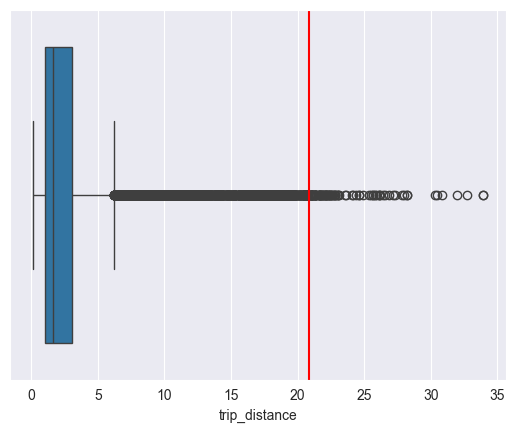

In [742]:
sns.boxplot(data=df, x="trip_distance"), plt.axvline(distance_upper_limit, color="r");

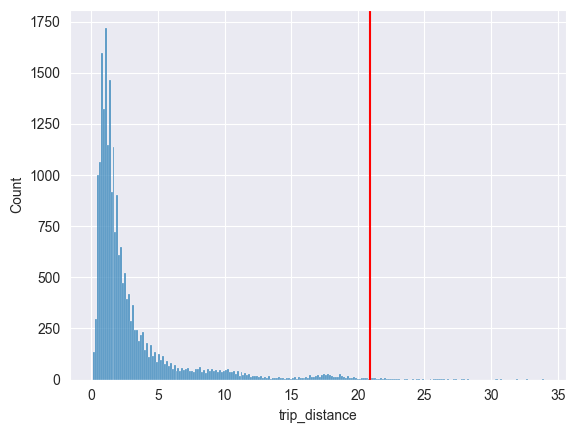

In [743]:
sns.histplot(data=df, x="trip_distance"), plt.axvline(distance_upper_limit, color="r");

# Trip Duration

In [744]:
df["trip_duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 3600


In [745]:
df.trip_duration.describe()

count    22426.000000
mean         0.284873
std          1.027788
min          0.000278
25%          0.112500
50%          0.187500
75%          0.307708
max         23.992500
Name: trip_duration, dtype: float64

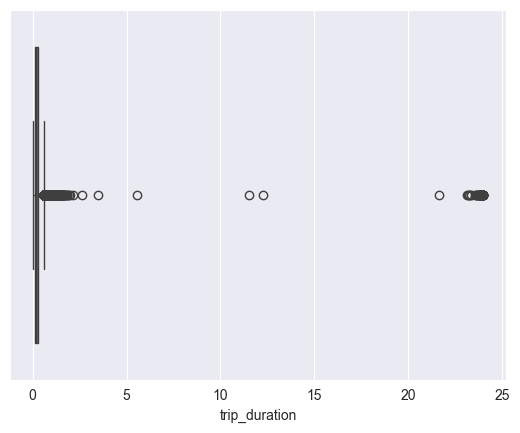

In [746]:
sns.boxplot(data=df, x="trip_duration");

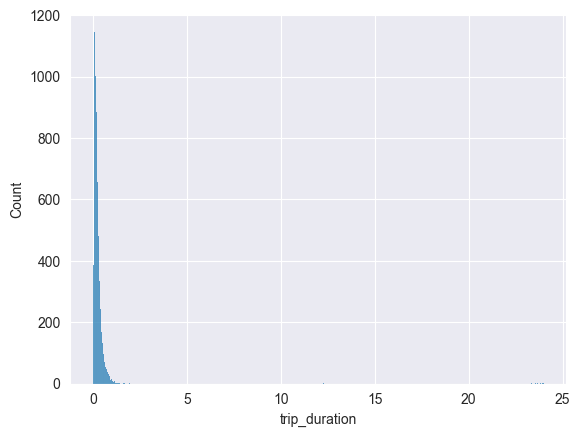

In [747]:
sns.histplot(data=df, x="trip_duration");

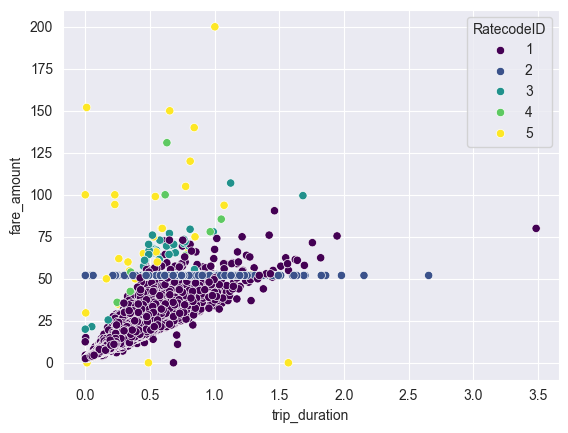

In [748]:
sns.scatterplot(
    data=df[(df.fare_amount < 999) & (df["trip_duration"] < 5)],
    x="trip_duration",
    y="fare_amount",
    hue="RatecodeID",
    palette="viridis",
);

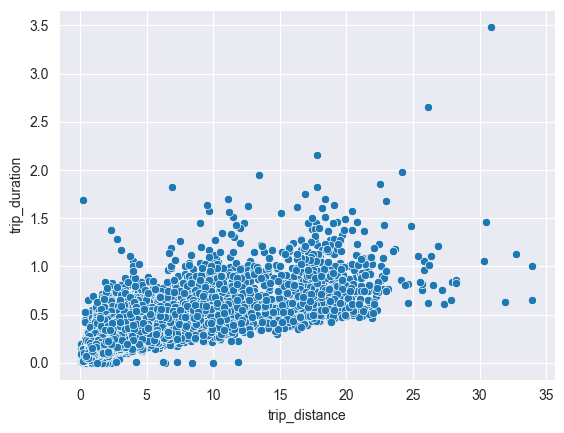

In [749]:
sns.scatterplot(
    data=df[(df.fare_amount < 999) & (df["trip_duration"] < 5)],
    y="trip_duration",
    x="trip_distance",
);


In [750]:
df[df["trip_duration"] > 5].shape[0]

44

### Average Speed

In [751]:
df["av_speed"] = df["trip_distance"] / df["trip_duration"]

In [752]:
df.av_speed.describe()

count    22426.000000
mean        13.866953
std        147.663951
min          0.013846
25%          7.308271
50%          9.871402
75%         13.628431
max      15120.000000
Name: av_speed, dtype: float64

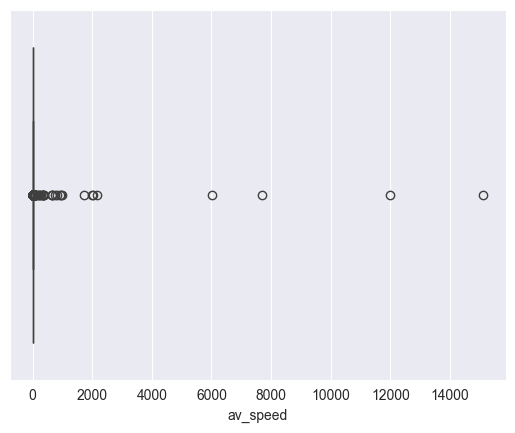

In [753]:
sns.boxplot(data=df, x="av_speed");

In [754]:
q1 = df.av_speed.quantile(0.25)
q3 = df.av_speed.quantile(0.75)

iqr = q3 - q1

speed_upper_limit = q3 + iqr * 1.5
speed_upper_limit

np.float64(23.108670883993355)

In [755]:
speed_upper_limit = 72.0

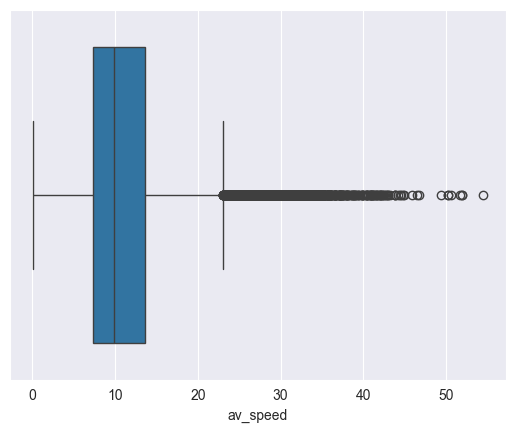

In [756]:
sns.boxplot(data=df[df.av_speed < speed_upper_limit], x="av_speed");

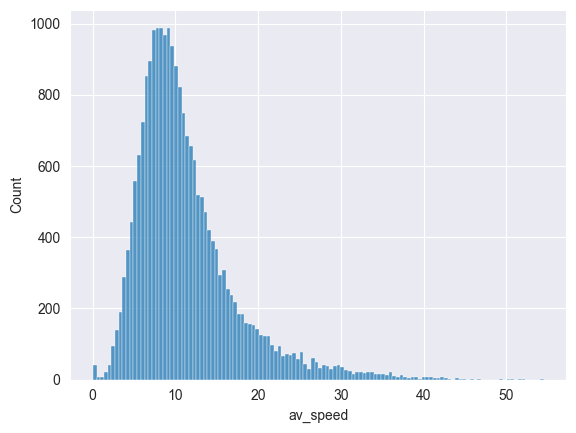

In [757]:
sns.histplot(data=df[df.av_speed < speed_upper_limit], x="av_speed");

In [758]:
df[["av_speed", "trip_distance", "fare_amount"]].sort_values("av_speed")[:6]

,av_speed,trip_distance,fare_amount
1010,0.013846,0.33,4.5
5478,0.026572,0.62,5.5
19164,0.028227,0.67,5.5
15579,0.030852,0.74,7.0
8712,0.036796,0.87,5.5
5370,0.038992,0.93,12.0


# Outlier removal

In [759]:
outlier_mask = (
    (df.fare_amount > fare_upper_limit)
    | (df.fare_amount < 1)
    | (df.trip_distance > distance_upper_limit)
    | (df.RatecodeID == 5)
    | (df.RatecodeID == 2)
    | (df.trip_duration > 5)
    | (df.av_speed > speed_upper_limit)
)

In [760]:
df = df[~outlier_mask]

# Correlation Analysis

In [761]:
df

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,RatecodeID,fare_amount,trip_duration,av_speed
0,2017-03-25 08:55:43,2017-03-25 09:09:47,3.34,1,13.0,0.234444,14.246445
1,2017-04-11 14:53:28,2017-04-11 15:19:58,1.80,1,16.0,0.441667,4.075472
2,2017-12-15 07:26:56,2017-12-15 07:34:08,1.00,1,6.5,0.120000,8.333333
3,2017-05-07 13:17:59,2017-05-07 13:48:14,3.70,1,20.5,0.504167,7.338843
4,2017-04-15 23:32:20,2017-04-15 23:49:03,4.37,1,16.5,0.278611,15.684945
...,...,...,...,...,...,...,...
22693,2017-08-10 22:20:04,2017-08-10 22:29:31,0.89,1,7.5,0.157500,5.650794
22694,2017-02-24 17:37:23,2017-02-24 17:40:39,0.61,1,4.0,0.054444,11.204082
22696,2017-09-04 14:54:14,2017-09-04 14:58:22,0.42,1,4.5,0.068889,6.096774
22697,2017-07-15 12:56:30,2017-07-15 13:08:26,2.36,1,10.5,0.198889,11.865922


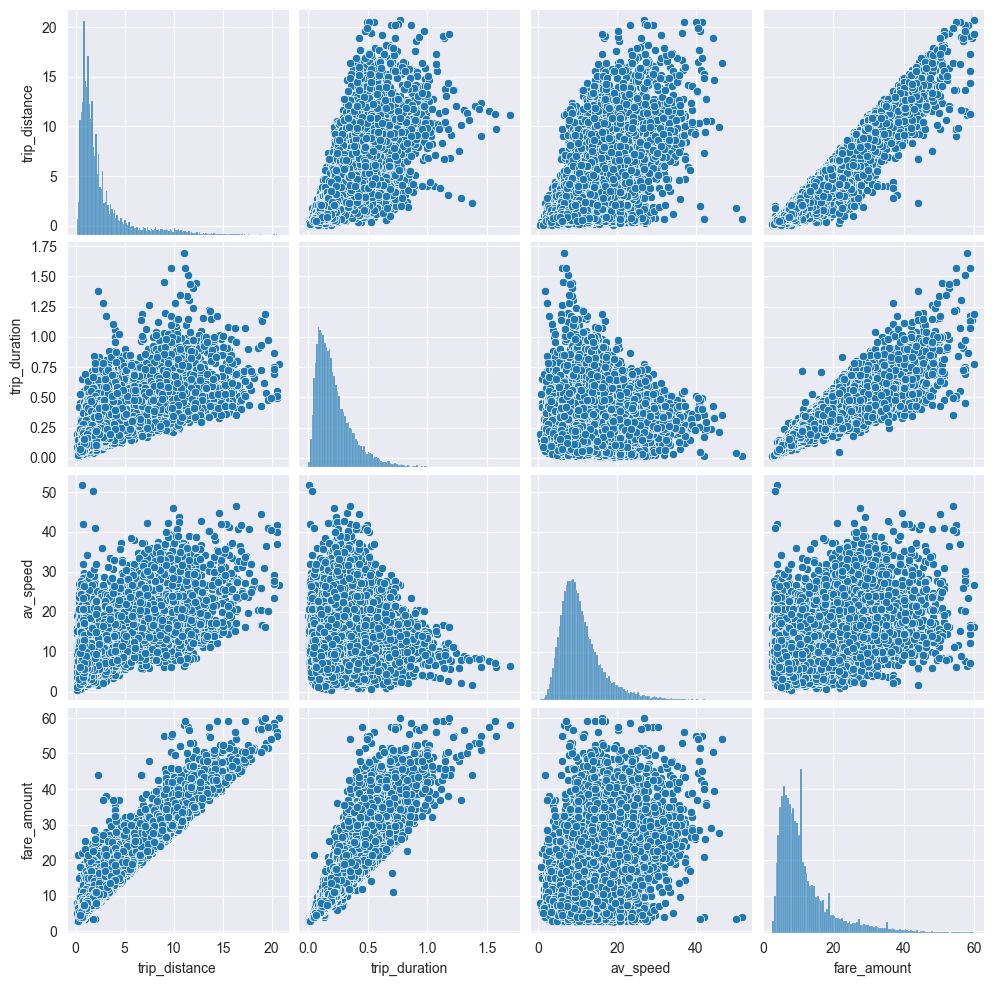

In [762]:
sns.pairplot(data=df[["trip_distance", "trip_duration", "av_speed", "fare_amount"]]);

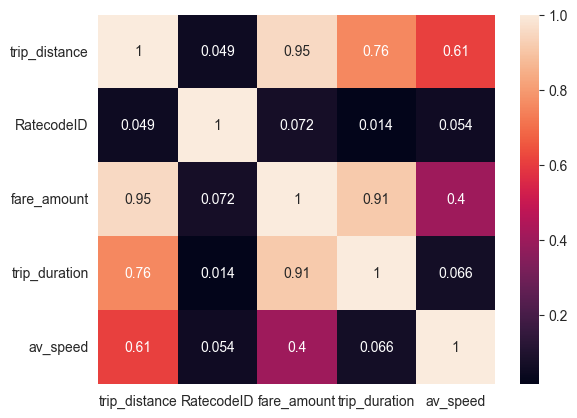

In [763]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True);

High collinearity: trip distance and duration

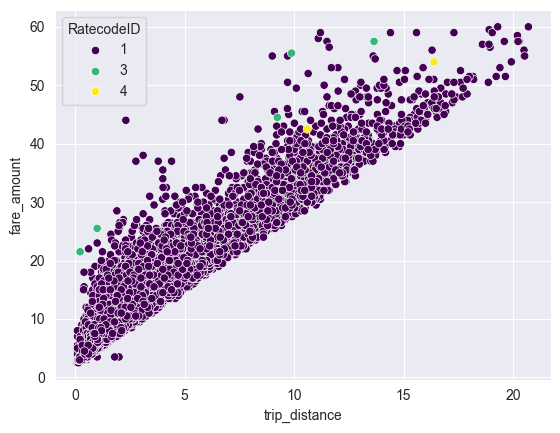

In [764]:
sns.scatterplot(
    data=df, x="trip_distance", y="fare_amount", hue="RatecodeID", palette="viridis"
);

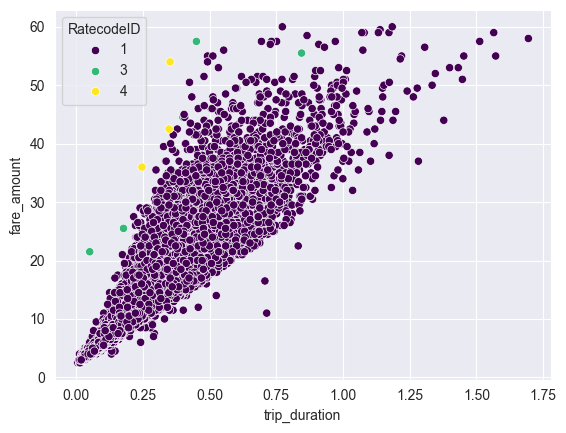

In [765]:
sns.scatterplot(
    data=df, x="trip_duration", y="fare_amount", hue="RatecodeID", palette="viridis"
);

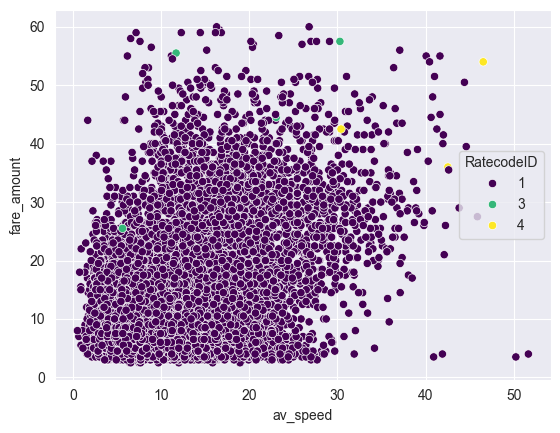

In [766]:
sns.scatterplot(
    data=df, x="av_speed", y="fare_amount", hue="RatecodeID", palette="viridis"
);

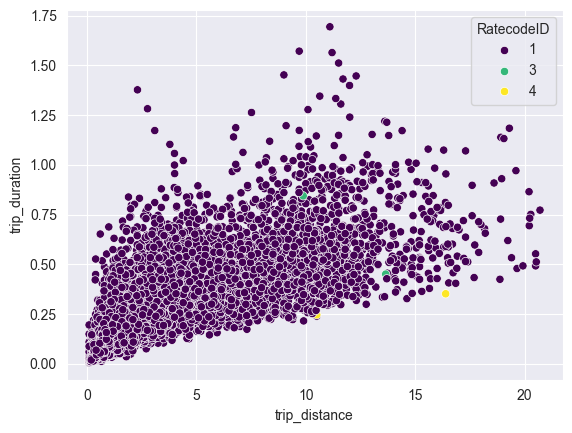

In [767]:
sns.scatterplot(
    data=df, x="trip_distance", y="trip_duration", hue="RatecodeID", palette="viridis"
);

In [768]:
df.groupby("RatecodeID").agg({"fare_amount": "median"})

,fare_amount
RatecodeID,
1,9.0
3,44.5
4,42.5


In [769]:
df.describe()

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,RatecodeID,fare_amount,trip_duration,av_speed
count,21771,21771,21771.000000,21771.000000,21771.000000,21771.000000,21771.000000
mean,2017-06-29 01:55:21.279178496,2017-06-29 02:08:55.239446784,2.535985,1.000873,11.771646,0.226100,10.951159
min,2017-01-01 00:08:25,2017-01-01 00:17:20,0.100000,1.000000,2.500000,0.005278,0.511364
25%,2017-03-29 23:20:58,2017-03-29 23:32:33.500000,0.990000,1.000000,6.500000,0.111111,7.248322
50%,2017-06-23 11:36:42,2017-06-23 12:00:06,1.600000,1.000000,9.000000,0.183333,9.729730
75%,2017-10-01 14:13:13.500000,2017-10-01 14:23:46.500000,2.890000,1.000000,14.000000,0.294167,13.258446
max,2017-12-31 23:45:30,2017-12-31 23:49:24,20.700000,4.000000,60.000000,1.694444,51.652174
std,NaN,NaN,2.653858,0.046456,8.047014,0.164305,5.528211


In [770]:
df.loc[:, "pickup_hr"] = df["tpep_pickup_datetime"].dt.hour

In [771]:
df.loc[:, "pickup_day"] = df["tpep_pickup_datetime"].dt.day

In [772]:
df.loc[:, "week_day"] = df["tpep_pickup_datetime"].dt.weekday

In [773]:
df.loc[:, "month"] = df["tpep_pickup_datetime"].dt.month

In [774]:
df["pickup_hr"].describe()

count    21771.000000
mean        13.726747
std          6.235507
min          0.000000
25%          9.000000
50%         14.000000
75%         19.000000
max         23.000000
Name: pickup_hr, dtype: float64

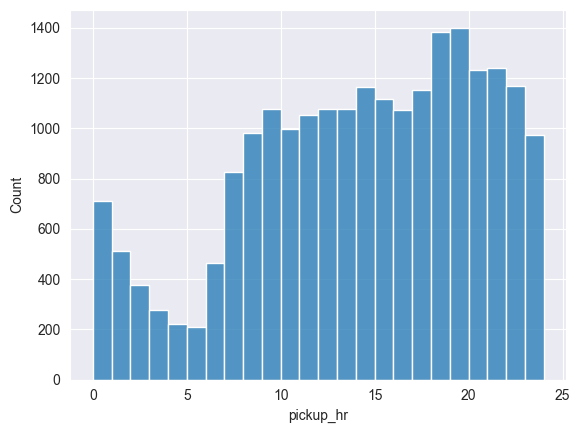

In [775]:
sns.histplot(data=df, x="pickup_hr", bins=range(0, 25, 1));

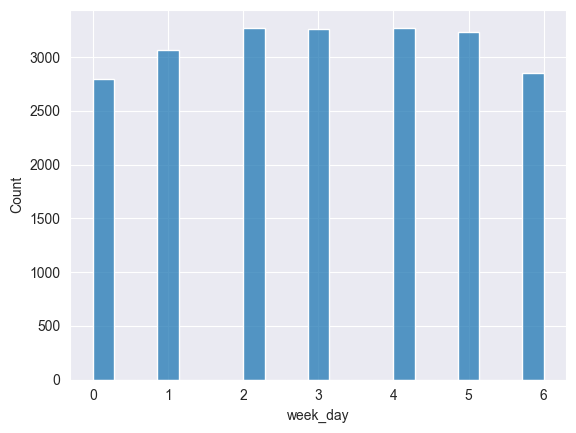

In [776]:
sns.histplot(data=df, x="week_day");

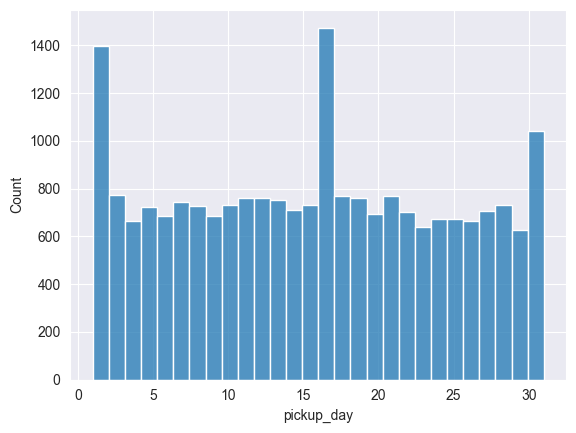

In [777]:
sns.histplot(data=df, x="pickup_day");

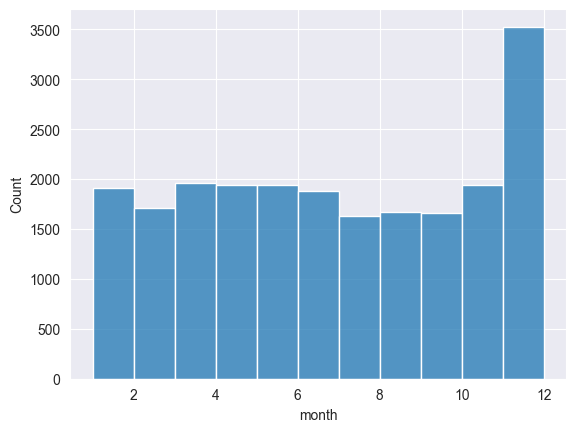

In [778]:
sns.histplot(data=df, x="month", bins=range(1, 13, 1));

In [779]:
df.groupby("month")["fare_amount"].agg(["mean", "median"])

,mean,median
month,,
1,11.317303,9.0
2,11.438561,9.0
3,11.672528,9.0
4,11.604124,9.0
5,12.305369,9.5
6,11.950213,9.5
7,11.705324,9.5
8,11.858944,9.5
9,11.680698,9.0


Doesnt look like datetime of pickup affect fares in any way, other than when very early in the mornings

In [ ]:
to_drop = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "pickup_day",
    "week_day",
    "month",
    "av_speed",
]

In [ ]:
df = df.drop(to_drop, axis=1)

In [782]:
df

,trip_distance,RatecodeID,fare_amount,trip_duration,pickup_hr
0,3.34,1,13.0,0.234444,8
1,1.80,1,16.0,0.441667,14
2,1.00,1,6.5,0.120000,7
3,3.70,1,20.5,0.504167,13
4,4.37,1,16.5,0.278611,23
...,...,...,...,...,...
22693,0.89,1,7.5,0.157500,22
22694,0.61,1,4.0,0.054444,17
22696,0.42,1,4.5,0.068889,14
22697,2.36,1,10.5,0.198889,12


In [783]:
df.describe()

,trip_distance,RatecodeID,fare_amount,trip_duration,pickup_hr
count,21771.000000,21771.000000,21771.000000,21771.000000,21771.000000
mean,2.535985,1.000873,11.771646,0.226100,13.726747
std,2.653858,0.046456,8.047014,0.164305,6.235507
min,0.100000,1.000000,2.500000,0.005278,0.000000
25%,0.990000,1.000000,6.500000,0.111111,9.000000
50%,1.600000,1.000000,9.000000,0.183333,14.000000
75%,2.890000,1.000000,14.000000,0.294167,19.000000
max,20.700000,4.000000,60.000000,1.694444,23.000000


In [793]:
df.fare_amount.value_counts().iloc[:3]

fare_amount
6.0    1158
6.5    1083
5.5    1075
Name: count, dtype: int64

In [ ]:
df.to_csv("data/processed/data.csv", index=False)